# PPO en Walker2d-v5 (MuJoCo)

**Objetivo.** Entrenar un agente con PPO (Proximal Policy Optimization) de Stable-Baselines3 sobre `Walker2d-v5`, documentar los hiperparámetros, el número de pasos y la semilla para poder reproducir el experimento, y compararlo contra un agente aleatorio evaluado con los mismos episodios.

**Por qué este entorno.** Walker2d-v5 es un entorno de control continuo del benchmark MuJoCo usado por Schulman et al. (2017); LunarLander y CartPole ya se trabajaron en clase.

**Entorno.**
- Observación: vector de 17 valores (posiciones y velocidades del torso y de las articulaciones, sin la posición horizontal).
- Acción: 6 torques continuos en $[-1, 1]$ (tres por pierna).
- Recompensa por paso: velocidad hacia adelante, más una bonificación de 1 mientras el agente está sano, menos un costo de control proporcional al cuadrado de los torques.
- Terminación: el episodio termina si el torso sale del rango saludable, o se trunca a 1 000 pasos.

## 1. Fundamentos teóricos

**Progresión de métodos.** REINFORCE estima el gradiente de la política con retornos de Monte Carlo, lo que produce una varianza alta. Actor-Critic añade una función de valor $V_\phi(s)$ como línea base para reducir esa varianza. PPO mantiene la estabilidad de Actor-Critic limitando cuánto cambia la política en cada actualización, y reutiliza cada rollout en varias épocas de minibatches.

**Ventaja con GAE.** La ventaja se estima como $\hat A_t = \sum_{l \ge 0} (\gamma\lambda)^l \delta_{t+l}$, con $\delta_t = R_t + \gamma V(s_{t+1}) - V(s_t)$. En este experimento $\gamma = 0.99$ y $\lambda = 0.95$.

**Objetivo recortado (clipped).**

$$
L^{CLIP}(\theta)=\hat{\mathbb E}_t\left[\min\left(r_t(\theta)\,\hat A_t,\ \mathrm{clip}\big(r_t(\theta),\,1-\epsilon,\,1+\epsilon\big)\,\hat A_t\right)\right],
\qquad r_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{old}}(a_t\mid s_t)}
$$

con $\epsilon = 0.2$. El recorte elimina el incentivo a llevar $r_t(\theta)$ fuera de $[1-\epsilon, 1+\epsilon]$, así que cada actualización se mantiene cerca de la política anterior.

**Política gaussiana.** Para acciones continuas, la red produce la media $\mu_\theta(s)$ de una distribución normal por dimensión, y la desviación estándar es un parámetro aprendido independiente del estado.

*Referencia:* Schulman, J., Wolski, F., Dhariwal, P., Radford, A., & Klimov, O. (2017). *Proximal Policy Optimization Algorithms*. arXiv:1707.06347.

## 2. Configuración del entorno de ejecución

Variables de entorno opcionales:
- `WALKER_SMOKE=1`: ejecución corta (4 096 pasos y 2 episodios de evaluación) para comprobar que el cuaderno corre de punta a punta. No es evidencia de aprendizaje.
- `TRAIN_SEED`: semilla de entrenamiento (por defecto 2026; debe ser no negativa y distinta de las semillas de evaluación).
- `WALKER_OUTPUT_DIR`: carpeta de salida (por defecto `results/walker_ppo` dentro del proyecto).

In [1]:
import os
import sys
from pathlib import Path


def _is_truthy(value):
    return str(value).strip().lower() in {"1", "true", "yes"}


SMOKE = _is_truthy(os.environ.get("WALKER_SMOKE", ""))
TRAIN_SEED = int(os.environ.get("TRAIN_SEED", "2026"))


def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "walker_rl.py").is_file():
            return candidate
    raise FileNotFoundError("walker_rl.py was not found in the working directory or its parents")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

OUTPUT_DIR = (
    Path(os.environ["WALKER_OUTPUT_DIR"]).resolve()
    if os.environ.get("WALKER_OUTPUT_DIR")
    else PROJECT_ROOT / "results" / "walker_ppo"
)

import walker_rl  # project helper; importing it creates no environment or directory

print("Modo smoke:", SMOKE)
print("Raíz del proyecto:", PROJECT_ROOT)
print("Directorio de salida:", OUTPUT_DIR)

Modo smoke: False
Raíz del proyecto: C:\Users\Alejandro Moncada\orca\workspaces\frogger-rl-lab\PPO
Directorio de salida: C:\Users\Alejandro Moncada\orca\workspaces\frogger-rl-lab\PPO\results\walker_ppo


## 3. Hiperparámetros y configuración

Hiperparámetros de Schulman et al. (2017) para tareas MuJoCo. Esta celda también escribe `config.json` con las versiones de los paquetes, para reproducir la corrida.

In [2]:
import json
import platform

import gymnasium
import mujoco
import numpy as np
import stable_baselines3
import torch

TOTAL_TIMESTEPS = 4_096 if SMOKE else 1_000_000
EVAL_EPISODES = 2 if SMOKE else 20
EVAL_SEEDS = [10_000 + i for i in range(EVAL_EPISODES)]
RANDOM_SEED = 424_242
DEVICE = "cpu"

if TRAIN_SEED < 0:
    raise ValueError("TRAIN_SEED must be non-negative")
if TRAIN_SEED in EVAL_SEEDS:
    raise ValueError("TRAIN_SEED must not be one of the held-out EVAL_SEEDS")

PPO_KWARGS = dict(
    n_steps=2048,
    batch_size=64,
    n_epochs=10,
    learning_rate=3e-4,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.0,
    vf_coef=0.5,
    policy_kwargs=dict(
        net_arch=dict(pi=[64, 64], vf=[64, 64]),
        activation_fn=torch.nn.Tanh,
    ),
)

print("| Parámetro | Valor |")
print("|---|---|")
for name, value in [
    ("TOTAL_TIMESTEPS", TOTAL_TIMESTEPS),
    ("TRAIN_SEED", TRAIN_SEED),
    ("EVAL_EPISODES", EVAL_EPISODES),
    ("RANDOM_SEED", RANDOM_SEED),
    ("n_steps", PPO_KWARGS["n_steps"]),
    ("batch_size", PPO_KWARGS["batch_size"]),
    ("n_epochs", PPO_KWARGS["n_epochs"]),
    ("learning_rate", PPO_KWARGS["learning_rate"]),
    ("gamma", PPO_KWARGS["gamma"]),
    ("gae_lambda", PPO_KWARGS["gae_lambda"]),
    ("clip_range", PPO_KWARGS["clip_range"]),
    ("ent_coef", PPO_KWARGS["ent_coef"]),
    ("vf_coef", PPO_KWARGS["vf_coef"]),
    ("net_arch", PPO_KWARGS["policy_kwargs"]["net_arch"]),
    ("activation_fn", "Tanh"),
    ("device", DEVICE),
]:
    print(f"| {name} | {value} |")

config = {
    "env_id": walker_rl.ENV_ID,
    "smoke": SMOKE,
    "total_timesteps": TOTAL_TIMESTEPS,
    "train_seed": TRAIN_SEED,
    "eval_episodes": EVAL_EPISODES,
    "eval_seeds": EVAL_SEEDS,
    "random_seed": RANDOM_SEED,
    "device": DEVICE,
    "hyperparameters": {
        **{key: value for key, value in PPO_KWARGS.items() if key != "policy_kwargs"},
        "policy_kwargs": {
            "net_arch": PPO_KWARGS["policy_kwargs"]["net_arch"],
            "activation_fn": "Tanh",
        },
    },
    "vecnormalize": {"norm_obs": True, "norm_reward": True, "gamma": 0.99},
    "package_versions": {
        "python": platform.python_version(),
        "gymnasium": gymnasium.__version__,
        "mujoco": mujoco.__version__,
        "stable_baselines3": stable_baselines3.__version__,
        "torch": torch.__version__,
        "numpy": np.__version__,
    },
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("config.json escrito en", OUTPUT_DIR)

| Parámetro | Valor |
|---|---|
| TOTAL_TIMESTEPS | 1000000 |
| TRAIN_SEED | 2026 |
| EVAL_EPISODES | 20 |
| RANDOM_SEED | 424242 |
| n_steps | 2048 |
| batch_size | 64 |
| n_epochs | 10 |
| learning_rate | 0.0003 |
| gamma | 0.99 |
| gae_lambda | 0.95 |
| clip_range | 0.2 |
| ent_coef | 0.0 |
| vf_coef | 0.5 |
| net_arch | {'pi': [64, 64], 'vf': [64, 64]} |
| activation_fn | Tanh |
| device | cpu |
config.json escrito en C:\Users\Alejandro Moncada\orca\workspaces\frogger-rl-lab\PPO\results\walker_ppo


## 4. Baseline: agente aleatorio

El agente aleatorio muestrea acciones uniformes del espacio de acción real, con un generador local y semilla fija. Se evalúa sobre las mismas semillas de evaluación que PPO, con recompensas crudas.

In [3]:
random_result = walker_rl.evaluate_policy(None, EVAL_SEEDS, random_seed=RANDOM_SEED)
random_return = random_result["metrics"]["return"]
print(
    f"Aleatorio: retorno {random_return['mean']:.1f} ± {random_return['std']:.1f} "
    f"sobre {random_result['num_episodes']} episodios"
)

Aleatorio: retorno -0.6 ± 5.6 sobre 20 episodios


## 5. Entrenamiento con PPO

El entorno de entrenamiento se envuelve en `VecNormalize` (normalización de observaciones y recompensas). El `Monitor` que agrega `make_vec_env` está debajo de esa envoltura, así que los retornos registrados son crudos. Un callback guarda el retorno y la longitud de cada episodio completado, junto con el paso de entrenamiento en que terminó.

In [4]:
import time

from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import VecNormalize


class EpisodeRecorder(BaseCallback):
    # Collects (timestep, raw return, length) from Monitor episode info.

    def __init__(self):
        super().__init__()
        self.rows = []

    def _on_step(self):
        for info in self.locals["infos"]:
            episode = info.get("episode")
            if episode is not None:
                self.rows.append((self.num_timesteps, float(episode["r"]), int(episode["l"])))
        return True


train_env = make_vec_env(walker_rl.make_env, n_envs=1, seed=TRAIN_SEED)
train_env = VecNormalize(train_env, norm_obs=True, norm_reward=True, gamma=0.99)

model = PPO("MlpPolicy", train_env, seed=TRAIN_SEED, device=DEVICE, **PPO_KWARGS)
recorder = EpisodeRecorder()

start = time.perf_counter()
model.learn(TOTAL_TIMESTEPS, callback=recorder)
training_seconds = time.perf_counter() - start

model.save(OUTPUT_DIR / "model.zip")
train_env.save(OUTPUT_DIR / "vecnormalize.pkl")
print(
    f"Entrenamiento: {TOTAL_TIMESTEPS} pasos en {training_seconds:.1f} s; "
    f"episodios completados: {len(recorder.rows)}"
)

Entrenamiento: 1000000 pasos en 1402.7 s; episodios completados: 3163


## 6. Evaluación del agente entrenado

Las estadísticas de `VecNormalize` se congelan (sin actualizarse) y sólo se normalizan las observaciones. Las recompensas se reportan crudas. La evaluación usa las mismas semillas que el baseline aleatorio.

In [5]:
train_env.training = False
train_env.norm_reward = False

ppo_result = walker_rl.evaluate_policy(model, EVAL_SEEDS, vecnormalize=train_env)
ppo_return = ppo_result["metrics"]["return"]
print(
    f"PPO: retorno {ppo_return['mean']:.1f} ± {ppo_return['std']:.1f} "
    f"sobre {ppo_result['num_episodes']} episodios"
)

PPO: retorno 4743.5 ± 76.4 sobre 20 episodios


## 7. Comparación contra el baseline

La tabla resume media y desviación del retorno y la longitud media de los episodios. `comparison.csv` guarda cada episodio y `comparison.json` guarda los resúmenes.

In [6]:
import csv

policy_results = {"random": random_result, "ppo": ppo_result}

comparison = {
    "eval_seeds": EVAL_SEEDS,
    "training_seconds": round(training_seconds, 2),
    "policies": {
        name: {
            "num_episodes": result["num_episodes"],
            "seeds": [episode["seed"] for episode in result["episodes"]],
            "metrics": result["metrics"],
        }
        for name, result in policy_results.items()
    },
}
(OUTPUT_DIR / "comparison.json").write_text(json.dumps(comparison, indent=2), encoding="utf-8")

with (OUTPUT_DIR / "comparison.csv").open("w", newline="", encoding="utf-8") as fh:
    writer = csv.DictWriter(
        fh, fieldnames=["policy", "seed", "return", "length", "terminated", "truncated"]
    )
    writer.writeheader()
    for name, result in policy_results.items():
        for episode in result["episodes"]:
            writer.writerow(
                {
                    "policy": name,
                    "seed": episode["seed"],
                    "return": episode["return"],
                    "length": episode["length"],
                    "terminated": episode["terminated"],
                    "truncated": episode["truncated"],
                }
            )

print("| Política | Episodios | Retorno medio ± desv. | Longitud media |")
print("|---|---|---|---|")
for name, result in policy_results.items():
    length = result["metrics"]["length"]
    ret = result["metrics"]["return"]
    print(
        f"| {name} | {result['num_episodes']} | "
        f"{ret['mean']:.1f} ± {ret['std']:.1f} | {length['mean']:.1f} |"
    )

| Política | Episodios | Retorno medio ± desv. | Longitud media |
|---|---|---|---|
| random | 20 | -0.6 ± 5.6 | 19.7 |
| ppo | 20 | 4743.5 ± 76.4 | 997.0 |


## 8. Curva de aprendizaje

Se grafica el retorno crudo de cada episodio contra el paso de entrenamiento, con una media móvil (ventana de 20 episodios, o menos si hay pocos) y una línea horizontal en la media del agente aleatorio. Si no hay episodios completados, el título lo indica.

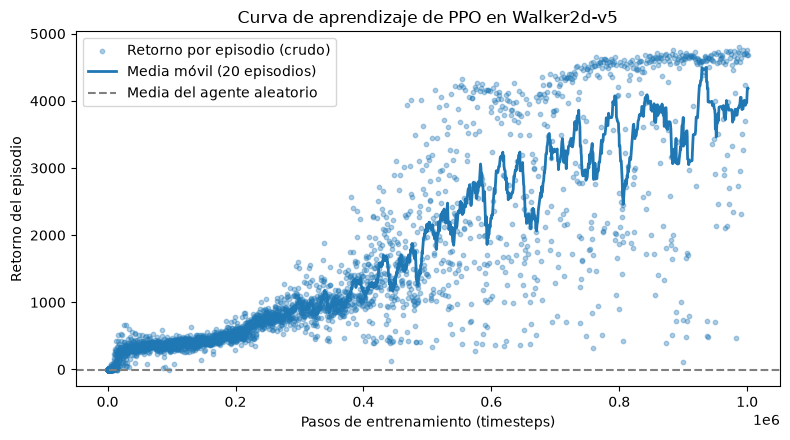

In [7]:
import matplotlib.pyplot as plt
import numpy as np

timesteps = [row[0] for row in recorder.rows]
returns = [row[1] for row in recorder.rows]
lengths = [row[2] for row in recorder.rows]


def moving_average(values, window):
    averages = []
    for index in range(len(values)):
        first = max(0, index - window + 1)
        averages.append(float(np.mean(values[first:index + 1])))
    return averages


window = min(20, max(1, len(returns)))
averages = moving_average(returns, window)

with (OUTPUT_DIR / "curve.csv").open("w", newline="", encoding="utf-8") as fh:
    writer = csv.writer(fh)
    writer.writerow(["timestep", "episode_return", "episode_length", "moving_average"])
    writer.writerows(zip(timesteps, returns, lengths, averages))

fig, ax = plt.subplots(figsize=(8, 4.5))
if returns:
    ax.scatter(timesteps, returns, s=10, alpha=0.35, label="Retorno por episodio (crudo)")
    ax.plot(timesteps, averages, linewidth=2, label=f"Media móvil ({window} episodios)")
    title = "Curva de aprendizaje de PPO en Walker2d-v5"
else:
    title = "Curva de aprendizaje de PPO en Walker2d-v5: sin episodios completados"
ax.axhline(random_return["mean"], linestyle="--", color="gray", label="Media del agente aleatorio")
ax.set_title(title)
ax.set_xlabel("Pasos de entrenamiento (timesteps)")
ax.set_ylabel("Retorno del episodio")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "curve.png", dpi=120)
plt.show()

## 9. Episodio de demostración (opcional)

Se graba un episodio del agente entrenado en `walker.gif`. Se usan las mismas estadísticas congeladas de `VecNormalize`. Se limita a 300 cuadros (60 en modo smoke). Si Pillow no está disponible, la celda omite el GIF.

In [8]:
MAX_FRAMES = 60 if SMOKE else 300
GIF_PATH = OUTPUT_DIR / "walker.gif"

try:
    from PIL import Image
except ImportError:
    Image = None
    print("Pillow no está instalado: se omite walker.gif.")

if Image is not None:
    gif_env = walker_rl.make_env(render_mode="rgb_array")
    try:
        obs, _ = gif_env.reset(seed=EVAL_SEEDS[0])
        frames = [Image.fromarray(gif_env.render())]
        done = False
        while not done and len(frames) < MAX_FRAMES:
            action = model.predict(train_env.normalize_obs(obs), deterministic=True)[0]
            obs, _, terminated, truncated, _ = gif_env.step(action)
            done = terminated or truncated
            frames.append(Image.fromarray(gif_env.render()))
    finally:
        gif_env.close()

    frames[0].save(GIF_PATH, save_all=True, append_images=frames[1:], duration=33, loop=0)
    print(f"walker.gif guardado con {len(frames)} cuadros")

train_env.close()

walker.gif guardado con 300 cuadros


## 10. Interpretación y limitaciones

**Comparación** (20 episodios de evaluación con las semillas 10000–10019, retorno crudo sin normalizar):

| Política | Episodios | Retorno medio ± desv. | Largo medio ± desv. |
|---|---|---|---|
| Aleatoria | 20 | −0.57 ± 5.59 | 19.7 ± 5.9 |
| PPO (determinista) | 20 | 4743.5 ± 76.4 | 997.0 ± 13.1 |

**Curva de aprendizaje** (retorno de cada episodio de entrenamiento contra los pasos, con media móvil):

- **0 a 0.35 M pasos:** subida lenta y constante; la media móvil llega a unos 960 hacia 0.35 M.
- **0.35 a 0.7 M pasos:** crecimiento rápido y ruidoso; la media de los episodios de esta fase es de unos 1860.
- **Después de 0.7 M pasos:** los mejores episodios se estabilizan en una meseta de 4500 a 4800; la media de los últimos 50 episodios de entrenamiento es de unos 3980.

**Por qué el retorno de entrenamiento es menor que el de evaluación:** durante el entrenamiento las acciones se muestrean de la distribución gaussiana de la política, con ruido de exploración. En la evaluación se usa la acción media (determinista), que suele ser más estable.

**Limitaciones:**

- Se usó una sola semilla de entrenamiento (2026). Otras semillas pueden dar resultados distintos; no se afirma robustez frente a la semilla.
- La evaluación usa 20 episodios. La desviación describe la variabilidad entre episodios de un mismo modelo, no entre corridas de entrenamiento.
- Un largo medio de ≈ 1000 pasos significa que la mayoría de los episodios de PPO llega al límite de 1000 pasos: el caminante ya no cae dentro del horizonte evaluado.
- Se usan los hiperparámetros de Schulman et al. (2017) para MuJoCo, sin ajuste propio.

## 11. Cierre

PPO me serviría para el Agente Inversor porque los pesos de un portafolio son acciones continuas, que una política gaussiana o softmax puede producir, y el recorte da actualizaciones estables. Antes habría que considerar que los mercados no son estacionarios, que los métodos on-policy tienen baja eficiencia muestral, y validar con evaluación walk-forward contra un baseline buy-and-hold.